In [1]:
%pip install -q datasets opencv-python-headless

In [2]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
tf.keras.utils.set_random_seed(42)


In [3]:
def muestra(split, cantidad):
    ds = load_dataset("HuggingFaceM4/FairFace", "0.25", split=split, streaming=True)
    ds = ds.shuffle(seed=42, buffer_size=1000)
    X, y = [], []
    for fila in ds:
        if fila['age'] < 3:
            continue
        X.append(np.asarray(fila['image'].convert('RGB').resize((224,224))))
        y.append(fila['gender'])
        if len(y) == cantidad:
            break
    return np.array(X), np.array(y)
X_train,y_train = muestra('train',2000)
X,y = muestra('validation',800)
X_val,X_test,y_val,y_test = train_test_split(X,y,test_size=0.5,random_state=42,stratify=y)
print(X_train.shape,X_val.shape,X_test.shape)


README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

(2000, 224, 224, 3) (400, 224, 224, 3) (400, 224, 224, 3)


In [4]:
base = tf.keras.applications.MobileNetV2(weights='imagenet',include_top=False,input_shape=(224,224,3))
base.trainable = False
modelo = tf.keras.Sequential([tf.keras.layers.Input((224,224,3)),tf.keras.layers.Rescaling(1/127.5,offset=-1),base,tf.keras.layers.GlobalAveragePooling2D(),tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dropout(0.2),tf.keras.layers.Dense(2,activation='softmax')])
modelo.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
modelo.summary()
historial = modelo.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=4,batch_size=32)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/4
63/63 ━━━━━━━━━━━━━━━━━━━━ 49s 389ms/step - accuracy: 0.6810 - loss: 0.6236 - val_accuracy: 0.7450 - val_loss: 0.5043
Epoch 2/4
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.7755 - loss: 0.4779 - val_accuracy: 0.7450 - val_loss: 0.4938
Epoch 3/4
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7960 - loss: 0.4333 - val_accuracy: 0.7275 - val_loss: 0.5212
Epoch 4/4
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.8345 - loss: 0.3744 - val_accuracy: 0.7450 - val_loss: 0.5190


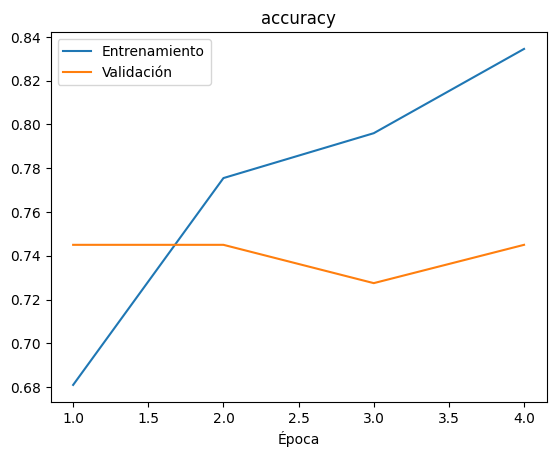

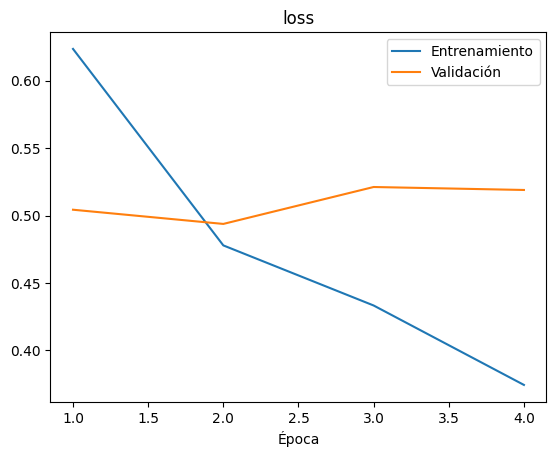

13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 294ms/step
Accuracy de prueba: 74.75%
              precision    recall  f1-score   support

        Male       0.76      0.77      0.77       216
      Female       0.73      0.72      0.72       184

    accuracy                           0.75       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.75      0.75      0.75       400



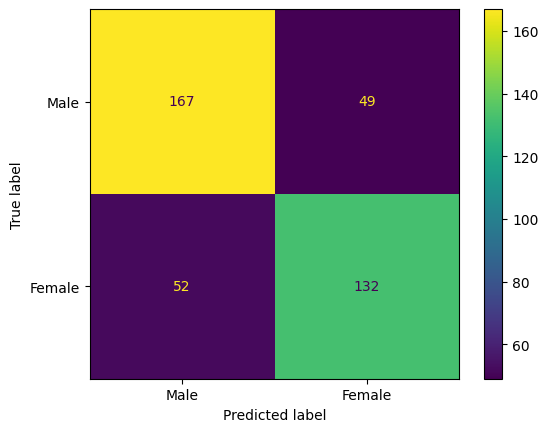

In [5]:
for metrica in ['accuracy','loss']:
    plt.figure()
    plt.plot(range(1,5),historial.history[metrica],label='Entrenamiento')
    plt.plot(range(1,5),historial.history['val_'+metrica],label='Validación')
    plt.xlabel('Época'); plt.title(metrica); plt.legend(); plt.show()
p = modelo.predict(X_test, batch_size=32)
pred = p.argmax(axis=1)
print(f'Accuracy de prueba: {accuracy_score(y_test,pred):.2%}')
print(classification_report(y_test,pred,labels=[0,1],target_names=['Male','Female'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=[0,1],display_labels=['Male','Female']); plt.show()


In [6]:
# Probabilidades de las etiquetas del conjunto de prueba, sin inferir identidad real
for i in range(10):
    print(f'Muestra {i}: Male={p[i,0]:.1%}, Female={p[i,1]:.1%}, etiqueta original={y_test[i]}')
modelo.save('/content/modelo_fairface.keras')


Muestra 0: Male=4.6%, Female=95.4%, etiqueta original=1
Muestra 1: Male=52.9%, Female=47.1%, etiqueta original=1
Muestra 2: Male=1.7%, Female=98.3%, etiqueta original=1
Muestra 3: Male=97.4%, Female=2.6%, etiqueta original=0
Muestra 4: Male=96.9%, Female=3.1%, etiqueta original=0
Muestra 5: Male=10.8%, Female=89.2%, etiqueta original=0
Muestra 6: Male=57.0%, Female=43.0%, etiqueta original=1
Muestra 7: Male=20.0%, Female=80.0%, etiqueta original=1
Muestra 8: Male=14.7%, Female=85.3%, etiqueta original=0
Muestra 9: Male=72.8%, Female=27.2%, etiqueta original=0


In [7]:
import urllib.request
url='https://media.githubusercontent.com/media/opencv/opencv_zoo/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx'
path='/content/yunet.onnx'
urllib.request.urlretrieve(url,path)
detector=cv2.FaceDetectorYN.create(path,'',(320,320),0.60,0.3,5000)
def dibujar(frame):
    h,w=frame.shape[:2]; detector.setInputSize((w,h))
    _,faces=detector.detect(frame)
    for f in ([] if faces is None else faces):
        x,y,a,b=map(int,f[:4]); s=float(f[-1]); color=(255,0,0) if s>=.85 else (180,105,255)
        cv2.rectangle(frame,(x,y),(x+a,y+b),color,2)
        cv2.putText(frame,f'Rostro {s:.1%}',(max(0,x),max(20,y-8)),cv2.FONT_HERSHEY_SIMPLEX,.6,color,2)
    return frame


In [13]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode, b64encode
import numpy as np
import cv2
import json

display(Javascript("""
window.iniciarCamara = async function() {

    const div = document.createElement('div');
    const video = document.createElement('video');
    const imagen = document.createElement('img');
    const boton = document.createElement('button');
    const canvas = document.createElement('canvas');

    boton.textContent = 'Detener cámara';
    imagen.style.width = '640px';
    imagen.style.maxWidth = '100%';

    window.activo = true;

    const stream = await navigator.mediaDevices.getUserMedia({
        video: {width: 640, height: 480},
        audio: false
    });

    video.srcObject = stream;
    await video.play();

    div.appendChild(imagen);
    div.appendChild(boton);
    document.body.appendChild(div);

    window.obtenerFrame = function() {

        if (!window.activo) return null;

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        return canvas.toDataURL('image/jpeg', 0.8);
    };

    window.mostrar = function(datos) {
        imagen.src = datos;

        google.colab.output.setIframeHeight(
            document.documentElement.scrollHeight, true
        );
        return true;
    };

    window.detenerCamara = function() {
        window.activo = false;
        stream.getTracks().forEach(t => t.stop());
        return true;
    };

    boton.onclick = window.detenerCamara;

    return true;
};
"""))

# Procesamiento continuo con OpenCV
try:

    eval_js("iniciarCamara()")

    while True:

        datos = eval_js("obtenerFrame()")

        if datos is None:
            break

        frame = cv2.imdecode(
            np.frombuffer(
                b64decode(datos.split(",")[1]),
                dtype=np.uint8
            ),
            cv2.IMREAD_COLOR
        )

        if frame is None:
            continue

        # Aplicar detección facial
        salida = dibujar(frame)

        # Compatibilidad si dibujar devuelve una tupla
        if isinstance(salida, tuple):
            salida = salida[0]

        ok, buf = cv2.imencode(".jpg", salida)

        if ok:
            resultado = b64encode(buf).decode("utf-8")

            url = "data:image/jpeg;base64," + resultado

            eval_js(f"mostrar({json.dumps(url)})")

except KeyboardInterrupt:
    print("Cámara detenida")

except Exception as error:
    print("Error:", error)

finally:
    try:
        eval_js("detenerCamara()")
    except Exception:
        pass


<IPython.core.display.Javascript object>